# **1. Google Drive 연결**

In [1]:
# ============================================================
# 낚시성 기사 탐지 - 데이터 전처리 (Google Colab)
# ============================================================
# 사용법:
# 1. Google Drive에 AI Hub zip 파일들 업로드
# 2. 아래 DATA_PATH를 실제 경로로 수정
# 3. 셀 순서대로 실행
# ============================================================

from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


# **2. 경로 설정**

In [2]:
# ⚠️ 아래 경로를 본인의 드라이브 경로로 수정하세요!

import os

# === 여기를 수정하세요! ===
# 예: '/content/drive/MyDrive/캡스톤/데이터/Training/2.라벨링데이터'
DATA_PATH = '/content/drive/MyDrive/2026 4-1 캡스톤/DATA/Validation'

# 경로 확인
if os.path.exists(DATA_PATH):
    files = os.listdir(DATA_PATH)
    print(f"✅ 경로 확인 완료! 파일/폴더 {len(files)}개 발견")
    for f in files[:10]:
        print(f"  - {f}")
    if len(files) > 10:
        print(f"  ... 외 {len(files) - 10}개")
else:
    print("❌ 경로를 찾을 수 없습니다. DATA_PATH를 확인하세요!")

✅ 경로 확인 완료! 파일/폴더 43개 발견
  - VL_Part1_Clickbait_Auto_GB.zip
  - VL_Part1_Clickbait_Auto_EC.zip
  - VL_Part1_Clickbait_Auto_PO.zip
  - VL_Part1_Clickbait_Auto_ET.zip
  - VL_Part1_Clickbait_Auto_LC.zip
  - VL_Part1_Clickbait_Auto_IS.zip
  - VL_Part1_Clickbait_Auto_SO.zip
  - VL_Part1_Clickbait_Direct_EC.zip
  - VL_Part1_Clickbait_Direct_GB.zip
  - VL_Part1_Clickbait_Direct_LC.zip
  ... 외 33개


# **3. ZIP 파일 압축 해제**

In [3]:
import zipfile
import glob

# zip 파일 찾기
zip_files = glob.glob(os.path.join(DATA_PATH, '*.zip'))
print(f"📦 ZIP 파일 {len(zip_files)}개 발견")

# 압축 해제할 폴더
EXTRACT_PATH = '/content/clickbait_data_val'
os.makedirs(EXTRACT_PATH, exist_ok=True)

# 압축 해제
for i, zf in enumerate(zip_files):
    fname = os.path.basename(zf)
    print(f"[{i+1}/{len(zip_files)}] {fname} 압축 해제 중...")
    try:
        with zipfile.ZipFile(zf, 'r') as z:
            z.extractall(EXTRACT_PATH)
    except Exception as e:
        print(f"  ⚠️ 오류: {e}")

print(f"\n✅ 압축 해제 완료! 경로: {EXTRACT_PATH}")

📦 ZIP 파일 42개 발견
[1/42] VL_Part1_Clickbait_Auto_GB.zip 압축 해제 중...
[2/42] VL_Part1_Clickbait_Auto_EC.zip 압축 해제 중...
[3/42] VL_Part1_Clickbait_Auto_PO.zip 압축 해제 중...
[4/42] VL_Part1_Clickbait_Auto_ET.zip 압축 해제 중...
[5/42] VL_Part1_Clickbait_Auto_LC.zip 압축 해제 중...
[6/42] VL_Part1_Clickbait_Auto_IS.zip 압축 해제 중...
[7/42] VL_Part1_Clickbait_Auto_SO.zip 압축 해제 중...
[8/42] VL_Part1_Clickbait_Direct_EC.zip 압축 해제 중...
[9/42] VL_Part1_Clickbait_Direct_GB.zip 압축 해제 중...
[10/42] VL_Part1_Clickbait_Direct_LC.zip 압축 해제 중...
[11/42] VL_Part1_Clickbait_Direct_ET.zip 압축 해제 중...
[12/42] VL_Part1_Clickbait_Direct_IS.zip 압축 해제 중...
[13/42] VL_Part1_Clickbait_Direct_SO.zip 압축 해제 중...
[14/42] VL_Part1_Clickbait_Direct_PO.zip 압축 해제 중...
[15/42] VL_Part1_NonClickbait_Auto_ET.zip 압축 해제 중...
[16/42] VL_Part1_NonClickbait_Auto_EC.zip 압축 해제 중...
[17/42] VL_Part1_NonClickbait_Auto_GB.zip 압축 해제 중...
[18/42] VL_Part1_NonClickbait_Auto_LC.zip 압축 해제 중...
[19/42] VL_Part1_NonClickbait_Auto_IS.zip 압축 해제 중...
[20/42] VL_Par

In [4]:
# 압축 해제 결과 확인
import glob
json_files = glob.glob(os.path.join(EXTRACT_PATH, '**', '*.json'), recursive=True)
print(f"JSON 파일 {len(json_files):,}개 발견")

# 폴더 구조 확인
for item in os.listdir(EXTRACT_PATH)[:10]:
    print(f"  - {item}")

JSON 파일 73,344개 발견
  - IS_M14_075405_L.json
  - SO_M07_459128_L.json
  - SO_M06_908839_L.json
  - PO_M08_850790_L.json
  - GB_M08_770744_L.json
  - GB_M12_641548_L.json
  - IS_M14_073750_L.json
  - IS_M10_647108_L.json
  - LC_M03_830448_L.json
  - SO_M06_422313_L.json


# **4. JSON 파일 파싱 → DataFrame 변환**

In [5]:
import json
import pandas as pd
from tqdm import tqdm

# JSON 파일 전체 찾기
json_files = glob.glob(os.path.join(EXTRACT_PATH, '**', '*.json'), recursive=True)
print(f"📄 JSON 파일 {len(json_files):,}개 발견")


# JSON 파싱 함수
def parse_json(filepath):
    """JSON 파일 하나를 파싱하여 딕셔너리로 반환"""
    try:
        with open(filepath, 'r', encoding='utf-8') as f:
            data = json.load(f)

        source = data.get('sourceDataInfo', {})
        label = data.get('labeledDataInfo', {})

        # 기본 정보
        row = {
            'newsID': source.get('newsID', ''),
            'newsCategory': source.get('newsCategory', ''),
            'newsSubcategory': source.get('newsSubcategory', ''),
            'newsTitle': source.get('newsTitle', ''),
            'newsContent': source.get('newsContent', ''),
            'partNum': source.get('partNum', ''),           # P1 또는 P2
            'processType': source.get('processType', ''),   # A(자동) 또는 D(직접)
            'processLevel': source.get('processLevel', ''),
            'sentenceCount': source.get('sentenceCount', 0),
            'clickbaitClass': label.get('clickbaitClass', -1),  # 0=낚시성, 1=정상
        }

        # Part1: 낚시성 제목 + 참조 문장 비율 계산
        if source.get('partNum') == 'P1':
            row['fakeTitle'] = label.get('newTitle', '')
            refer_info = label.get('referSentenceInfo', [])
            if refer_info:
                y_count = sum(1 for s in refer_info if s.get('referSentenceyn') == 'Y')
                row['referSentenceRatio'] = y_count / len(refer_info)
            else:
                row['referSentenceRatio'] = 0.0
            row['subjectConsistencyRatio'] = None  # Part1에는 없음

        # Part2: 주제 일관성 비율 계산
        elif source.get('partNum') == 'P2':
            row['fakeTitle'] = ''
            process_info = label.get('processSentenceInfo', [])
            if process_info:
                y_count = sum(1 for s in process_info if s.get('subjectConsistencyYn') == 'Y')
                row['subjectConsistencyRatio'] = y_count / len(process_info)
            else:
                row['subjectConsistencyRatio'] = 0.0
            row['referSentenceRatio'] = None  # Part2에는 없음

        return row

    except Exception as e:
        return None


# 전체 JSON 파싱 (진행바 포함)
print("🔄 JSON 파싱 중... (시간이 좀 걸릴 수 있습니다)")
rows = []
errors = 0

for filepath in tqdm(json_files, desc="파싱 진행"):
    result = parse_json(filepath)
    if result:
        rows.append(result)
    else:
        errors += 1

df = pd.DataFrame(rows)
print(f"\n✅ 파싱 완료!")
print(f"  - 성공: {len(df):,}건")
print(f"  - 실패: {errors:,}건")
print(f"  - 컬럼: {list(df.columns)}")

📄 JSON 파일 73,344개 발견
🔄 JSON 파싱 중... (시간이 좀 걸릴 수 있습니다)


파싱 진행: 100%|██████████| 73344/73344 [00:13<00:00, 5276.31it/s]



✅ 파싱 완료!
  - 성공: 73,344건
  - 실패: 0건
  - 컬럼: ['newsID', 'newsCategory', 'newsSubcategory', 'newsTitle', 'newsContent', 'partNum', 'processType', 'processLevel', 'sentenceCount', 'clickbaitClass', 'fakeTitle', 'referSentenceRatio', 'subjectConsistencyRatio']


# **5. 데이터 기본 통계 확인 (EDA)**

In [6]:
print("=" * 60)
print("📊 데이터 기본 통계")
print("=" * 60)

# 전체 크기
print(f"\n📌 전체 데이터: {len(df):,}건")

# Part 분포
print(f"\n📌 Part 분포:")
print(df['partNum'].value_counts().to_string())

# 낚시성 라벨 분포
print(f"\n📌 낚시성 라벨 분포 (0=낚시성, 1=정상):")
print(df['clickbaitClass'].value_counts().to_string())

# Part별 라벨 분포
print(f"\n📌 Part별 라벨 분포:")
print(pd.crosstab(df['partNum'], df['clickbaitClass'], margins=True).to_string())

# %%
# 뉴스 카테고리별 분포
print(f"\n📌 뉴스 카테고리별 분포:")
print(df['newsCategory'].value_counts().to_string())

# 가공 유형별 분포 (A=자동, D=직접)
print(f"\n📌 가공 유형별 분포 (A=자동, D=직접):")
print(df['processType'].value_counts().to_string())

# 문장 수 통계
print(f"\n📌 문장 수 통계:")
print(df['sentenceCount'].describe().to_string())

# 내부 일치도 피처 통계
print(f"\n📌 내부 일치도 피처 통계:")

# Part1: 참조 문장 비율
part1 = df[df['partNum'] == 'P1']
if 'referSentenceRatio' in part1.columns:
    print(f"\n[Part1] 참조 문장 비율 (referSentenceRatio):")
    p1_click = part1[part1['clickbaitClass']==0]['referSentenceRatio'].dropna()
    p1_normal = part1[part1['clickbaitClass']==1]['referSentenceRatio'].dropna()
    print(f"  낚시성(0): 평균 {p1_click.mean():.4f} ({len(p1_click):,}건)")
    print(f"  정상(1):   평균 {p1_normal.mean():.4f} ({len(p1_normal):,}건)")

# Part2: 주제 일관성 비율
part2 = df[df['partNum'] == 'P2']
if 'subjectConsistencyRatio' in part2.columns:
    print(f"\n[Part2] 주제 일관성 비율 (subjectConsistencyRatio):")
    p2_click = part2[part2['clickbaitClass']==0]['subjectConsistencyRatio'].dropna()
    p2_normal = part2[part2['clickbaitClass']==1]['subjectConsistencyRatio'].dropna()
    print(f"  낚시성(0): 평균 {p2_click.mean():.4f} ({len(p2_click):,}건)")
    print(f"  정상(1):   평균 {p2_normal.mean():.4f} ({len(p2_normal):,}건)")

📊 데이터 기본 통계

📌 전체 데이터: 73,344건

📌 Part 분포:
partNum
P2    36910
P1    36434

📌 낚시성 라벨 분포 (0=낚시성, 1=정상):
clickbaitClass
0    37006
1    36338

📌 Part별 라벨 분포:
clickbaitClass      0      1    All
partNum                            
P1              18265  18169  36434
P2              18741  18169  36910
All             37006  36338  73344

📌 뉴스 카테고리별 분포:
newsCategory
사회       14529
세계       11339
경제       10394
IT&과학    10122
정치        9977
연예        9042
생활&문화     7941

📌 가공 유형별 분포 (A=자동, D=직접):
processType
A    63317
D    10027

📌 문장 수 통계:
count    73344.000000
mean        13.975117
std          7.502784
min          6.000000
25%          8.000000
50%         12.000000
75%         17.000000
max         49.000000

📌 내부 일치도 피처 통계:

[Part1] 참조 문장 비율 (referSentenceRatio):
  낚시성(0): 평균 0.0386 (18,265건)
  정상(1):   평균 0.0000 (18,169건)

[Part2] 주제 일관성 비율 (subjectConsistencyRatio):
  낚시성(0): 평균 0.8161 (18,741건)
  정상(1):   평균 1.0000 (18,169건)


### TR과 동일한 한계점 발견

# **6. 시각화**

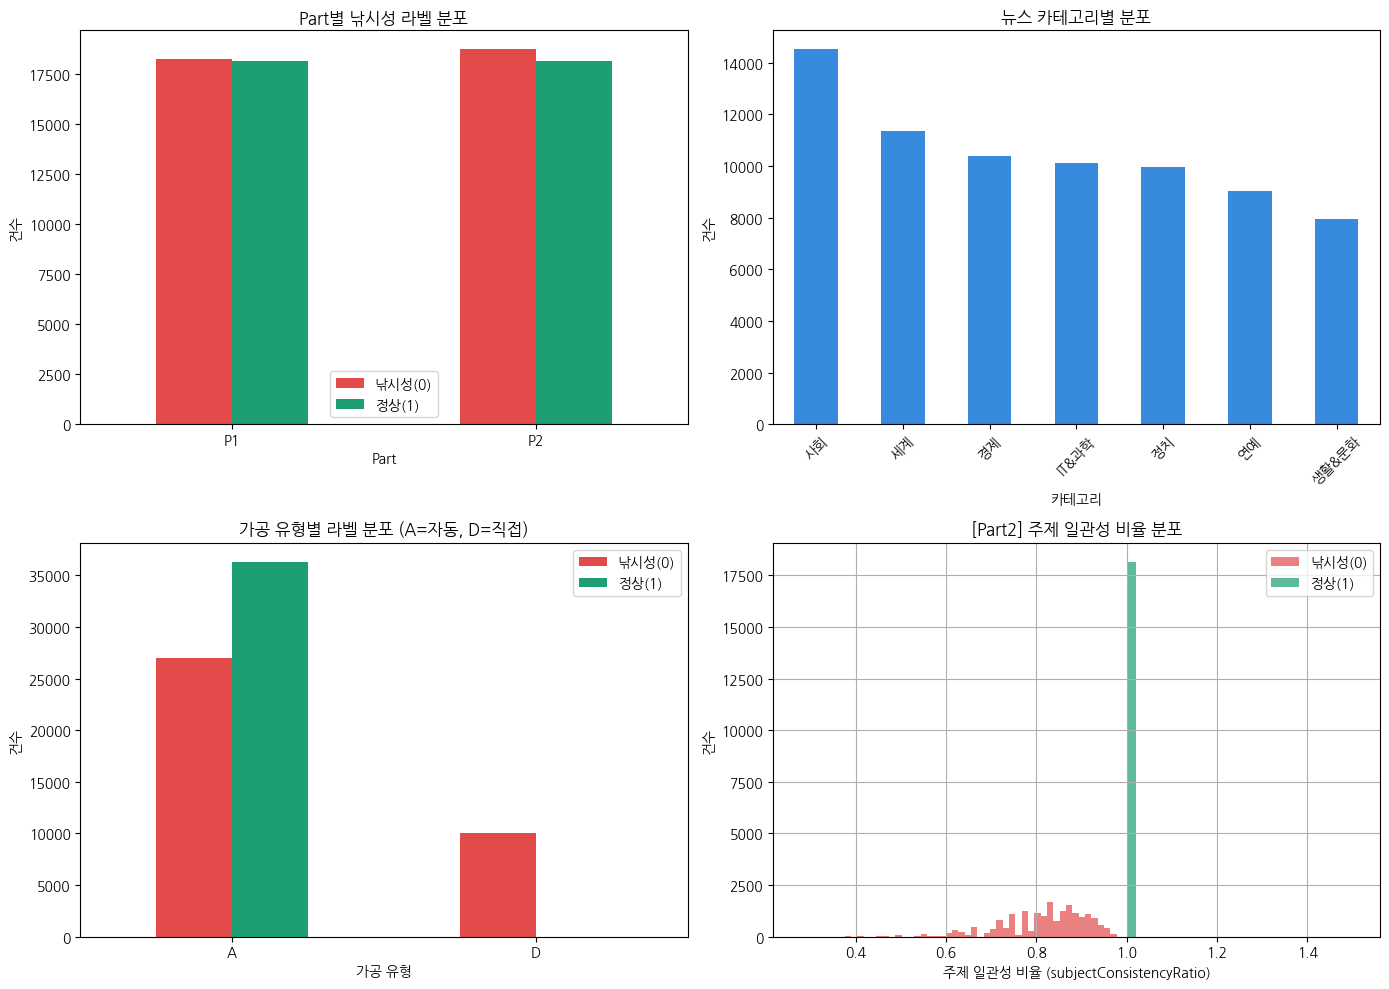

In [7]:
import matplotlib.pyplot as plt
import matplotlib
import subprocess
subprocess.run(['apt-get', '-y', '-qq', 'install', 'fonts-nanum'], capture_output=True)

import matplotlib.font_manager as fm
font_path = '/usr/share/fonts/truetype/nanum/NanumGothic.ttf'
fm.fontManager.addfont(font_path)
plt.rcParams['font.family'] = 'NanumGothic'
plt.rcParams['axes.unicode_minus'] = False



fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# (1) Part별 라벨 분포
ct = pd.crosstab(df['partNum'], df['clickbaitClass'])
ct.plot(kind='bar', ax=axes[0,0], color=['#E24B4A', '#1D9E75'])
axes[0,0].set_title('Part별 낚시성 라벨 분포')
axes[0,0].set_xlabel('Part')
axes[0,0].set_ylabel('건수')
axes[0,0].legend(['낚시성(0)', '정상(1)'])
axes[0,0].tick_params(axis='x', rotation=0)

# (2) 카테고리별 분포
df['newsCategory'].value_counts().plot(kind='bar', ax=axes[0,1], color='#378ADD')
axes[0,1].set_title('뉴스 카테고리별 분포')
axes[0,1].set_xlabel('카테고리')
axes[0,1].set_ylabel('건수')
axes[0,1].tick_params(axis='x', rotation=45)

# (3) 가공 유형별 × 라벨 분포
ct2 = pd.crosstab(df['processType'], df['clickbaitClass'])
ct2.plot(kind='bar', ax=axes[1,0], color=['#E24B4A', '#1D9E75'])
axes[1,0].set_title('가공 유형별 라벨 분포 (A=자동, D=직접)')
axes[1,0].set_xlabel('가공 유형')
axes[1,0].set_ylabel('건수')
axes[1,0].legend(['낚시성(0)', '정상(1)'])
axes[1,0].tick_params(axis='x', rotation=0)

# (4) Part2 주제 일관성 비율 분포
part2 = df[df['partNum'] == 'P2']
part2[part2['clickbaitClass']==0]['subjectConsistencyRatio'].dropna().hist(
    bins=50, alpha=0.7, ax=axes[1,1], color='#E24B4A', label='낚시성(0)')
part2[part2['clickbaitClass']==1]['subjectConsistencyRatio'].dropna().hist(
    bins=50, alpha=0.7, ax=axes[1,1], color='#1D9E75', label='정상(1)')
axes[1,1].set_title('[Part2] 주제 일관성 비율 분포')
axes[1,1].set_xlabel('주제 일관성 비율 (subjectConsistencyRatio)')
axes[1,1].set_ylabel('건수')
axes[1,1].legend()

plt.tight_layout()
plt.savefig('/content/drive/MyDrive/2026 4-1 캡스톤/DATA/Validation/VL_EDA_결과.png', dpi=150, bbox_inches='tight')
plt.show()

# **7. CSV 파일로 저장**

In [8]:
# CSV로 저장 (나중에 모델 학습에 사용)
csv_path = '/content/drive/MyDrive/VL_preprocessed.csv'

df.to_csv(csv_path, index=False, encoding='utf-8-sig')

print(f"💾 CSV 저장 완료: {csv_path}")
print(f"  - 전체: {len(df):,}건")
print(f"  - 파일 크기: {os.path.getsize(csv_path) / (1024*1024):.1f} MB")

💾 CSV 저장 완료: /content/drive/MyDrive/VL_preprocessed.csv
  - 전체: 73,344건
  - 파일 크기: 191.6 MB


# **8. 샘플 데이터 확인**

In [9]:
# Part1 낚시성 기사 샘플
print("=" * 60)
print("📰 [Part1] 낚시성 기사 샘플")
print("=" * 60)
sample_p1 = df[(df['partNum']=='P1') & (df['clickbaitClass']==0)].iloc[0]
print(f"원래 제목: {sample_p1['newsTitle']}")
print(f"낚시 제목: {sample_p1['fakeTitle']}")
print(f"카테고리:  {sample_p1['newsCategory']}")
print(f"참조문장비율: {sample_p1.get('referSentenceRatio', 'N/A')}")
print(f"본문 앞부분: {sample_p1['newsContent'][:200]}...")

# Part2 낚시성 기사 샘플
print("=" * 60)
print("📰 [Part2] 도메인 일관성 부족 기사 샘플")
print("=" * 60)
sample_p2 = df[(df['partNum']=='P2') & (df['clickbaitClass']==0)].iloc[0]
print(f"제목: {sample_p2['newsTitle']}")
print(f"카테고리: {sample_p2['newsCategory']}")
print(f"주제일관성비율: {sample_p2.get('subjectConsistencyRatio', 'N/A')}")
print(f"본문 앞부분: {sample_p2['newsContent'][:200]}...")

📰 [Part1] 낚시성 기사 샘플
원래 제목: 부동산 전문가들 “프롭테크·빅데이터 활용해야 앞서 나간다”
낚시 제목: 中 디스플레이 후방산업도 추월…한국보다 먼저 11세대 포토마스크 개발 나서
카테고리:  IT&과학
참조문장비율: 0.0
본문 앞부분: 아파트, 토지, 상가 분야 부동산 전문가들과 프롭테크 기업이 모여 올해 부동산 시장 전망 맥을 짚었다.
9일 서울 코엑스에서 열린 '2020 부동산 투자의 시작-프롭테크와 부동산 신들의 투자 이야기' 세미나에서 부동산 전문가 3인과 프롭테크 스타트업 대표 3인이 모여 부동산 투자 전략을 공개했다.
필명 '빠숑'으로 잘 알려진 김학렬 스마트튜브 부동산조사연구...
📰 [Part2] 도메인 일관성 부족 기사 샘플
제목: 日 “소녀상 철거 노력 없이 아베 평창행 기대 말라”
카테고리: 세계
주제일관성비율: 0.8571428571428571
본문 앞부분: 요미우리 등 日 언론 반발 NHK “한·일 관계 얼어붙을 것” 아사히 등은 “日도 노력해야” 한·일 위안부 합의를 부정한 문재인 대통령의 성명과 관련해 일본 정부는 재협상이든 추가 조치든 일절 받아들일 수 없다는 입장을 되풀이했다.
일본 언론도 한목소리로 한·일 관계 악화를 우려하며 한국에 합의 이행을 촉구했다.
니시무라 야스토시 관방 부장관은 28일 문 ...
